In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import scanpy.external as sce
import scipy
sc.settings.verbosity = 3
sc.logging.print_header()
sc.set_figure_params(dpi=100, dpi_save=600)
    
import matplotlib.pyplot as pl
from matplotlib import rcParams

import os

/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


scanpy==1.10.4 anndata==0.11.3 umap==0.5.7 numpy==1.26.4 scipy==1.15.1 pandas==2.2.3 scikit-learn==1.6.1 statsmodels==0.14.4 igraph==0.11.8 pynndescent==0.5.13


In [4]:
adata=sc.read('/mnt/c/Users/hyj/Downloads/NMCAD_MCAD.h5ad')
adata

AnnData object with n_obs × n_vars = 121707 × 38606
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset'
    var: 'gene_ids'

normalizing counts per cell
    finished (0:00:03)


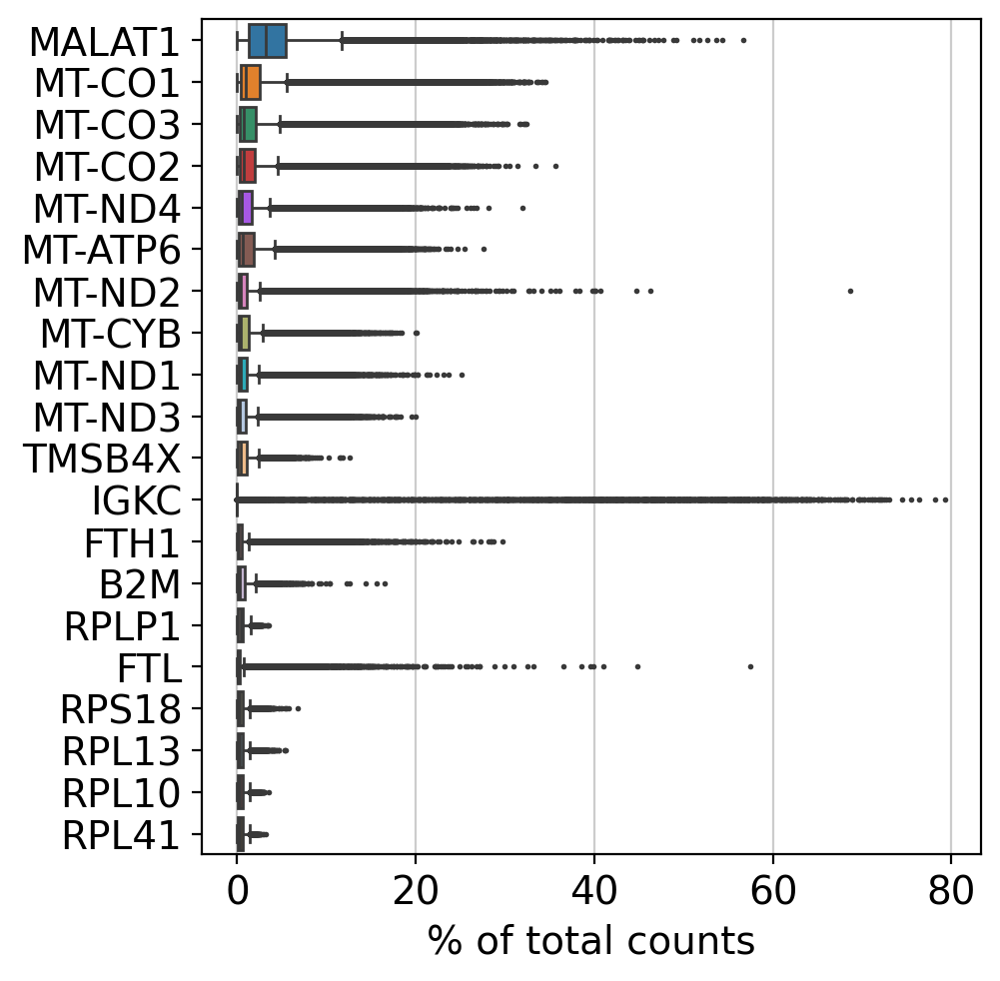

filtered out 4450 cells that have less than 100 genes expressed
filtered out 7754 genes that are detected in less than 25 cells


In [5]:
sc.pl.highest_expr_genes(adata, n_top=20)
sc.pp.filter_cells(adata, min_genes=100)
sc.pp.filter_genes(adata, min_cells=25)

In [6]:
adata.var['mt'] = adata.var_names.str.startswith('MT-')
adata.var['rpl'] = adata.var_names.str.startswith('RPL')
adata.var['rps'] = adata.var_names.str.startswith('RPS')
adata

AnnData object with n_obs × n_vars = 117257 × 30852
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'n_genes'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps'

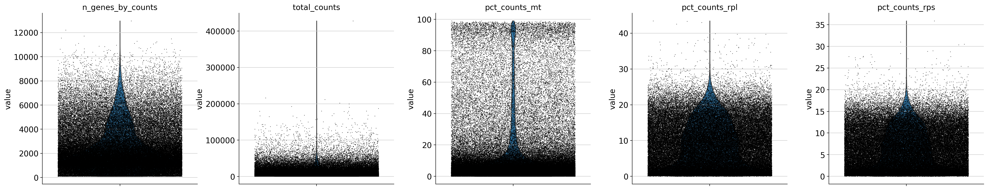

AnnData object with n_obs × n_vars = 117257 × 30852
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

In [7]:
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt','rpl','rps'], percent_top=None, log1p=False, inplace=True)
sc.pl.violin(adata, keys=['n_genes_by_counts', 'total_counts', 'pct_counts_mt','pct_counts_rpl','pct_counts_rps'], jitter=0.4, multi_panel=True)
adata

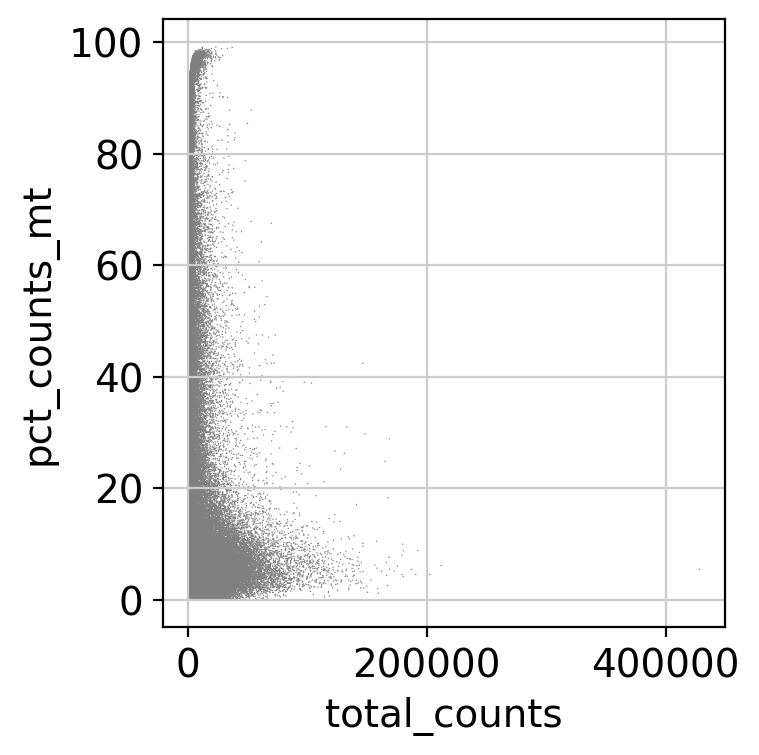

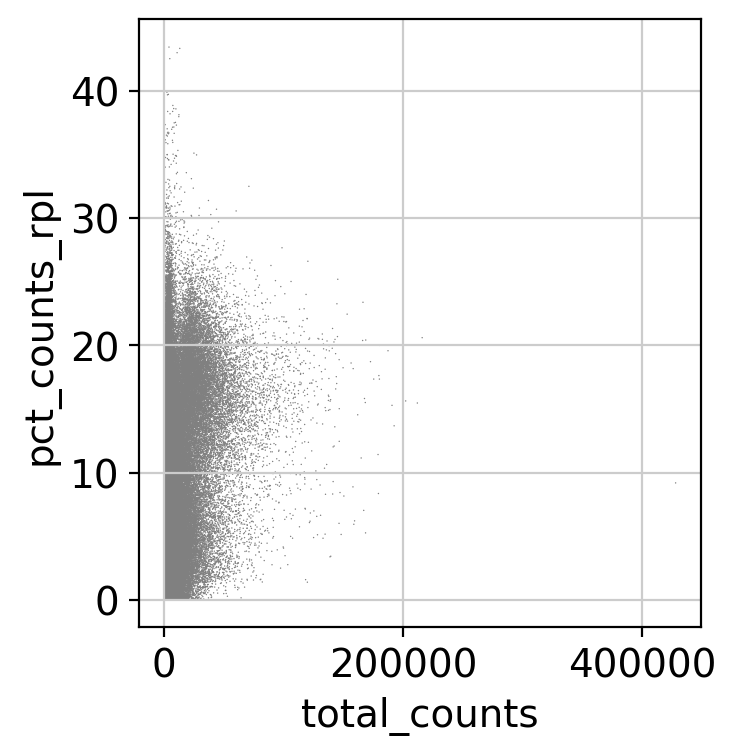

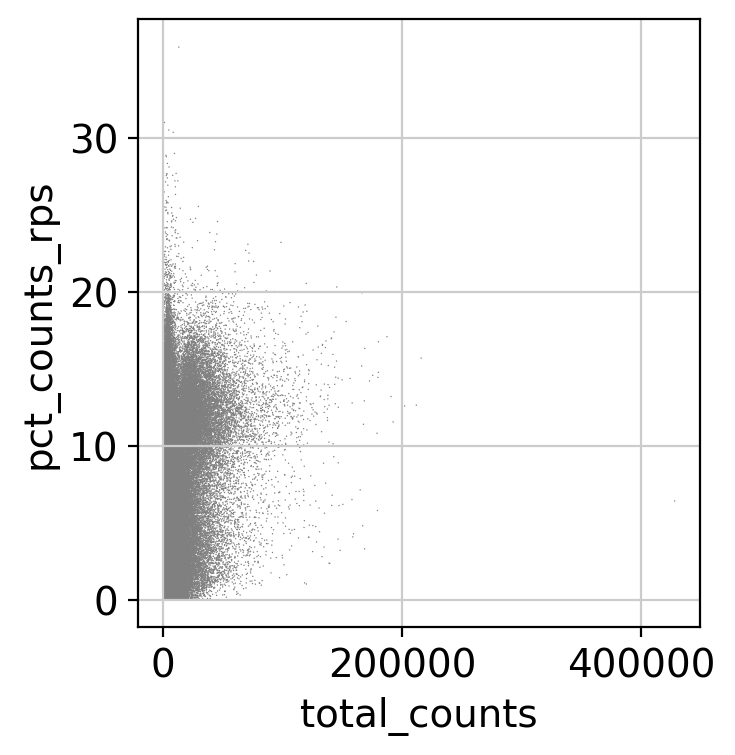

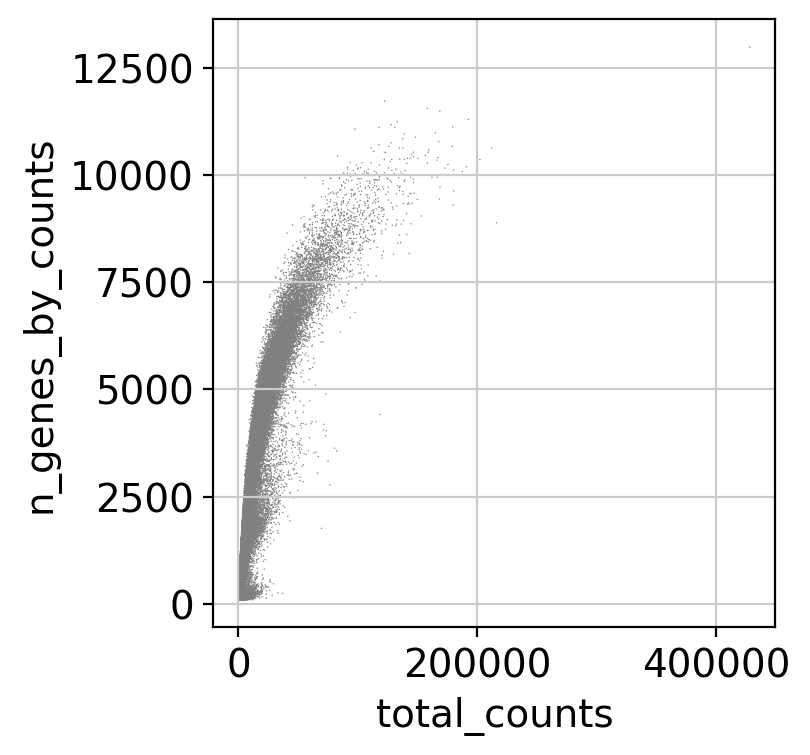

In [8]:
sc.pl.scatter(adata, x='total_counts', y='pct_counts_mt')
sc.pl.scatter(adata, x='total_counts', y='pct_counts_rpl')
sc.pl.scatter(adata, x='total_counts', y='pct_counts_rps')
sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts')

In [9]:
adata = adata[adata.obs.n_genes_by_counts < 12000, :]
adata = adata[adata.obs.pct_counts_mt < 50, :]
adata = adata[adata.obs.pct_counts_rpl < 50, :]
adata = adata[adata.obs.pct_counts_rps < 50, :]
adata

View of AnnData object with n_obs × n_vars = 106435 × 30852
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

In [10]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata

normalizing counts per cell
    finished (0:00:00)


AnnData object with n_obs × n_vars = 106435 × 30852
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'log1p'

extracting highly variable genes
    finished (0:00:06)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


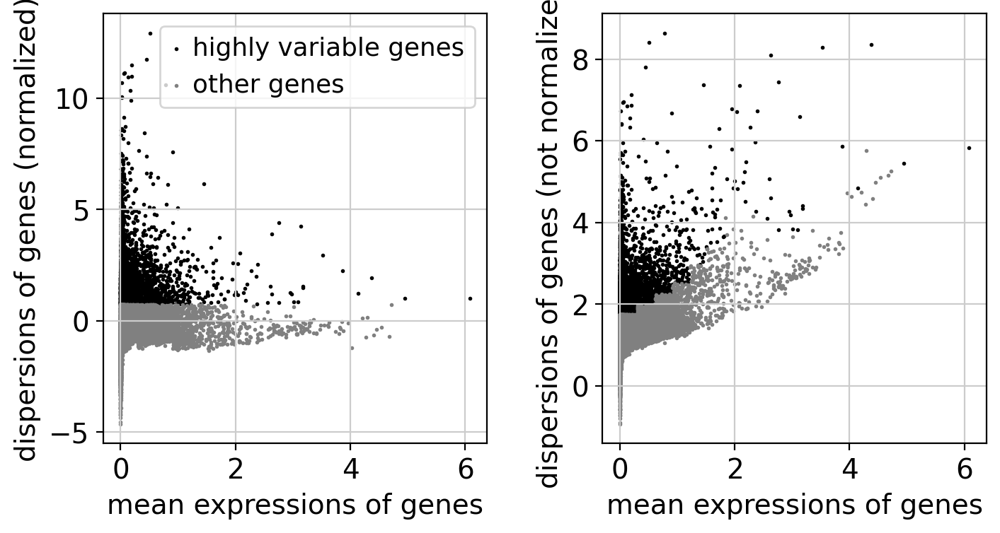

5000


AnnData object with n_obs × n_vars = 106435 × 30852
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'

In [11]:
sc.pp.highly_variable_genes(adata, n_top_genes=5000)
sc.pl.highly_variable_genes(adata)
print(sum(adata.var.highly_variable))
adata

In [12]:
adata.raw=adata

In [13]:
adata = adata[:, adata.var.highly_variable]
adata

View of AnnData object with n_obs × n_vars = 106435 × 5000
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'

In [14]:
sc.pp.regress_out(adata, keys=['total_counts', 'pct_counts_mt','pct_counts_rpl','pct_counts_rps'], n_jobs=96)
sc.pp.scale(adata, max_value=10)
adata

regressing out ['total_counts', 'pct_counts_mt', 'pct_counts_rpl', 'pct_counts_rps']
    sparse input is densified and may lead to high memory use
    finished (0:01:08)


AnnData object with n_obs × n_vars = 106435 × 5000
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg'

In [15]:
sc.tl.pca(adata, svd_solver='arpack')
sce.pp.harmony_integrate(adata, key='sample', basis='X_pca', adjusted_basis='X_pca_harmony')
adata.obsm['X_pca']=adata.obsm['X_pca_harmony']
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=50, knn=True)
sc.tl.leiden(adata, resolution=1, flavor="igraph", n_iterations=2, directed=False)
sc.tl.umap(adata)
adata

computing PCA
    with n_comps=50
    finished (0:00:38)


2025-10-23 23:14:51,671 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-10-23 23:14:59,317 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-10-23 23:14:59,888 - harmonypy - INFO - Iteration 1 of 10
2025-10-23 23:16:10,706 - harmonypy - INFO - Iteration 2 of 10
2025-10-23 23:17:21,339 - harmonypy - INFO - Iteration 3 of 10
2025-10-23 23:18:31,452 - harmonypy - INFO - Iteration 4 of 10
2025-10-23 23:19:38,954 - harmonypy - INFO - Iteration 5 of 10
2025-10-23 23:20:48,032 - harmonypy - INFO - Iteration 6 of 10
2025-10-23 23:21:34,572 - harmonypy - INFO - Iteration 7 of 10
2025-10-23 23:22:44,172 - harmonypy - INFO - Converged after 7 iterations


computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:39)
running Leiden clustering
    finished: found 30 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:09)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:01:04)


AnnData object with n_obs × n_vars = 106435 × 5000
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'leiden'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'leiden', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

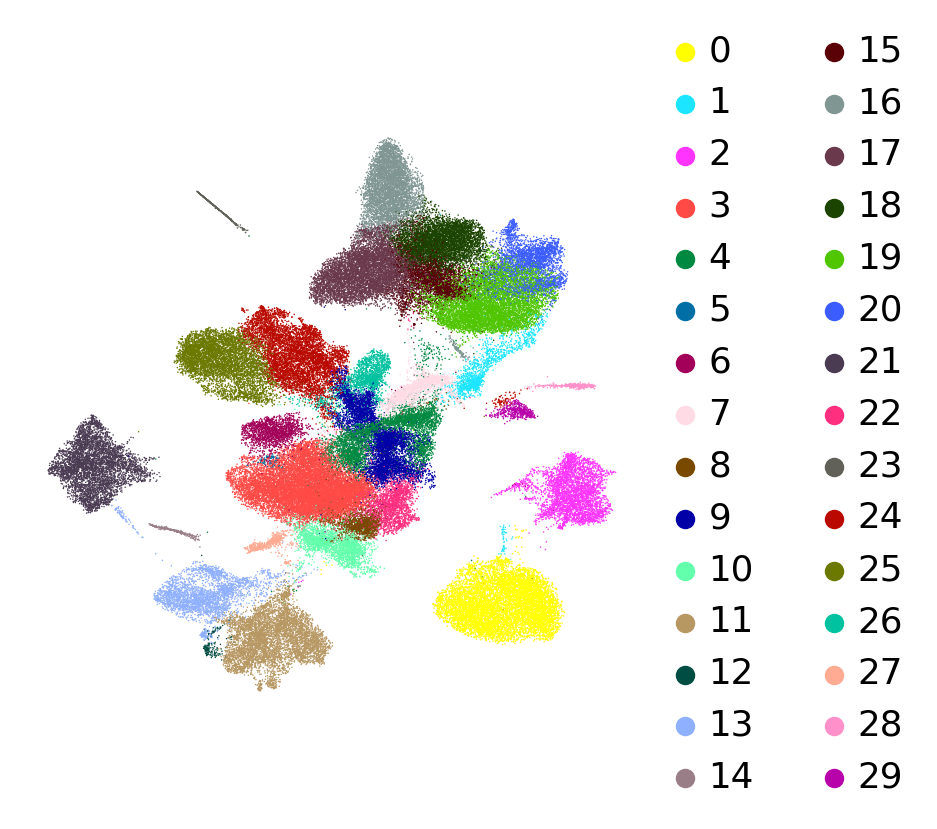

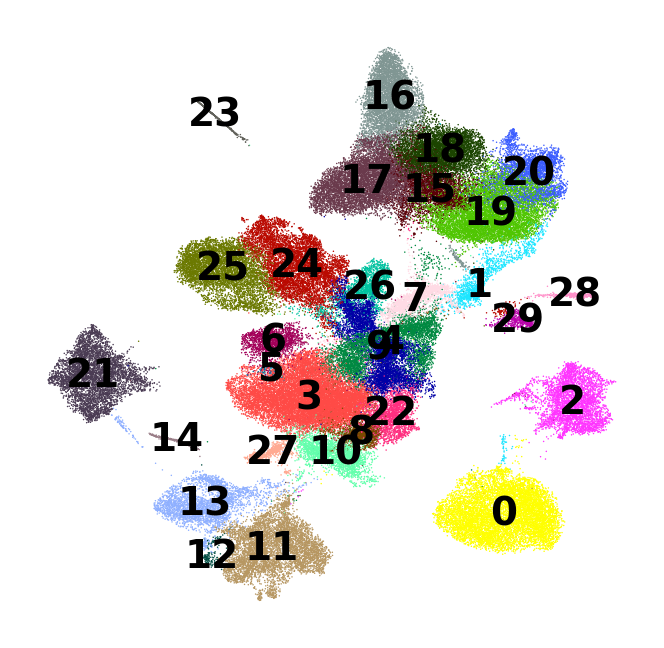

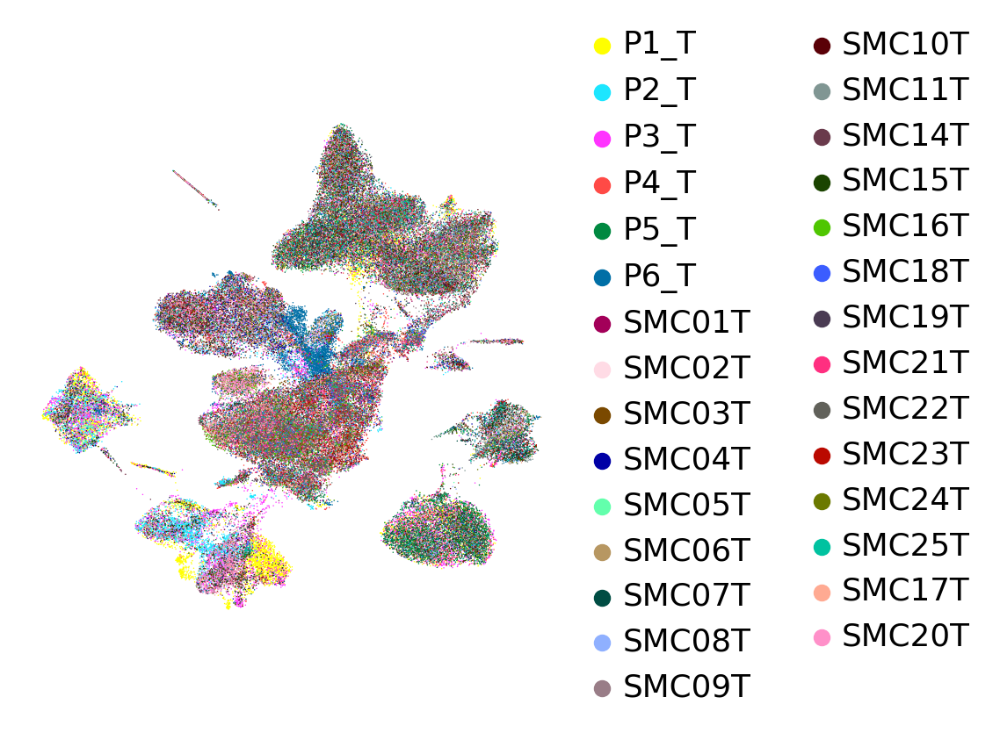

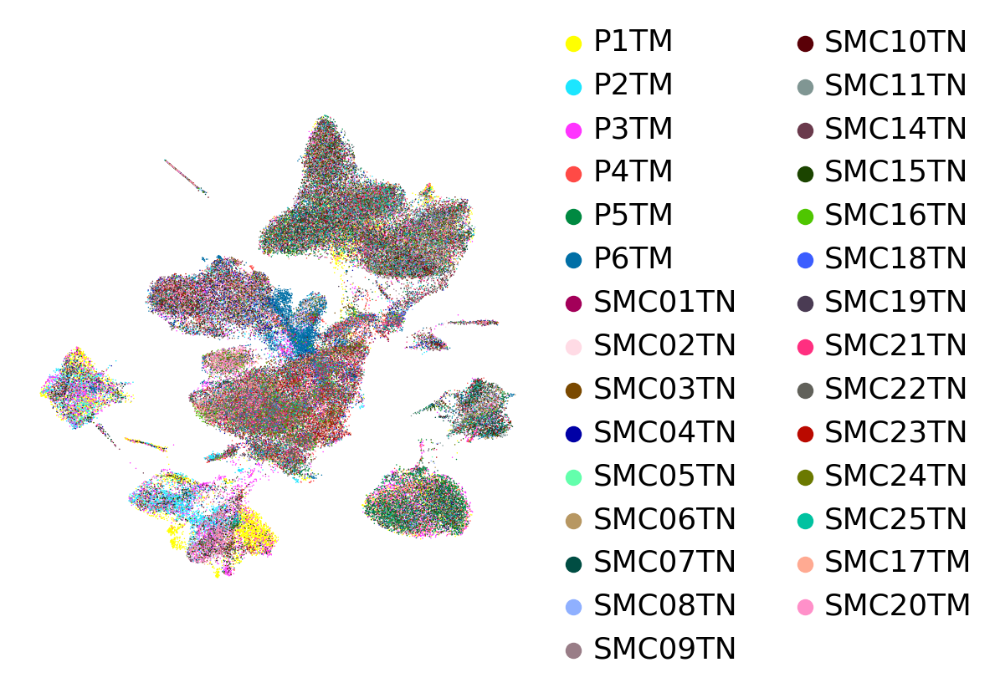

In [17]:
sc.pl.umap(adata, color=['leiden'], legend_loc='right margin', frameon=False, title='', use_raw=True, save='1.pdf')
sc.pl.umap(adata, color=['leiden'], legend_loc='on data', frameon=False, title='', use_raw=True)
sc.pl.umap(adata, color=['sample'], legend_loc='right margin', frameon=False, title='', use_raw=True)
sc.pl.umap(adata, color=['patient'], legend_loc='right margin', frameon=False, title='', use_raw=True, save='5.pdf')

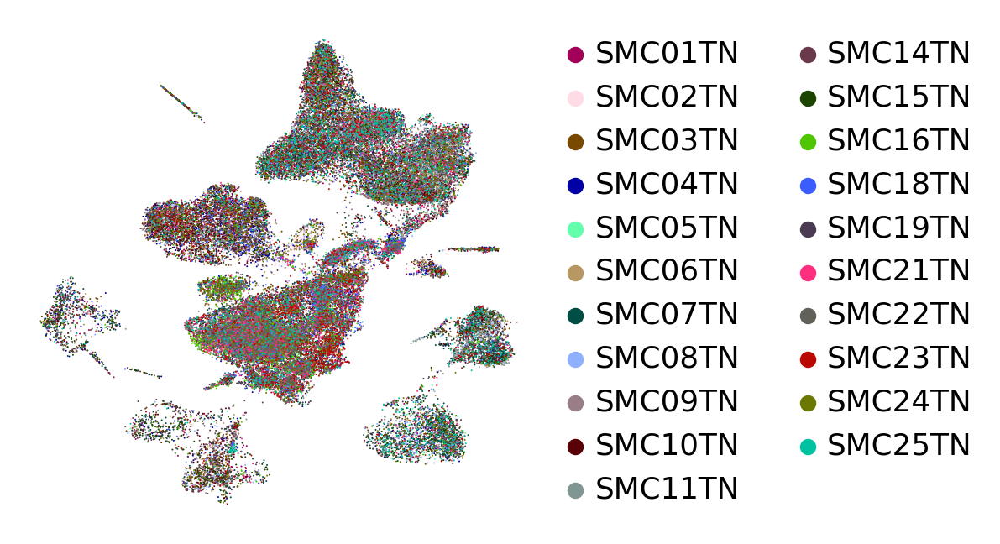

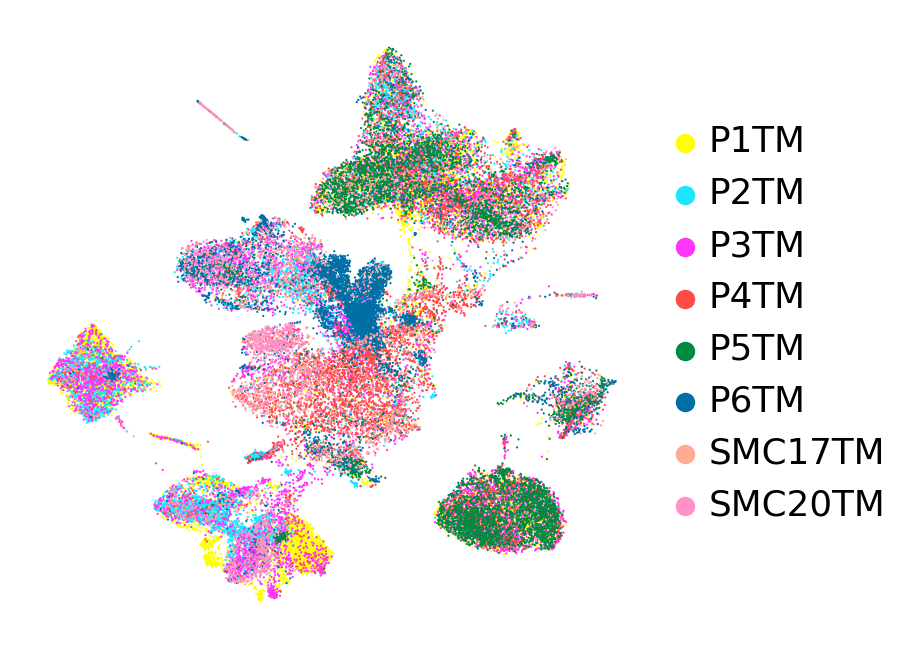

In [18]:
sc.pl.umap(adata[adata.obs['pathology'].isin(['NMCAD'])], color=['patient'], legend_loc='right margin', frameon=False, title='', use_raw=True, save='2.pdf')
sc.pl.umap(adata[adata.obs['pathology'].isin(['MCAD'])], color=['patient'], legend_loc='right margin', frameon=False, title='', use_raw=True, save='3.pdf')

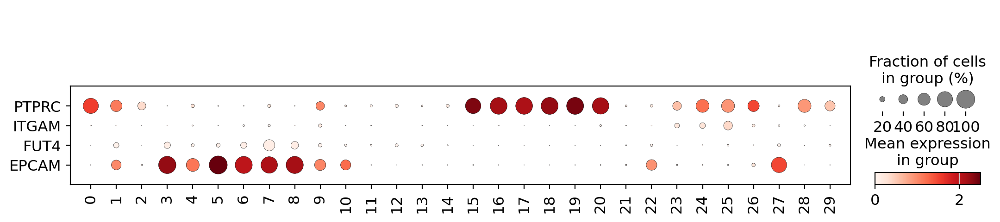

In [19]:
sc.pl.dotplot(adata, var_names=['PTPRC', 'ITGAM', 'FUT4', 'EPCAM'], groupby='leiden', use_raw=True, var_group_rotation=0, vmin=0, swap_axes=True, dot_min=0)

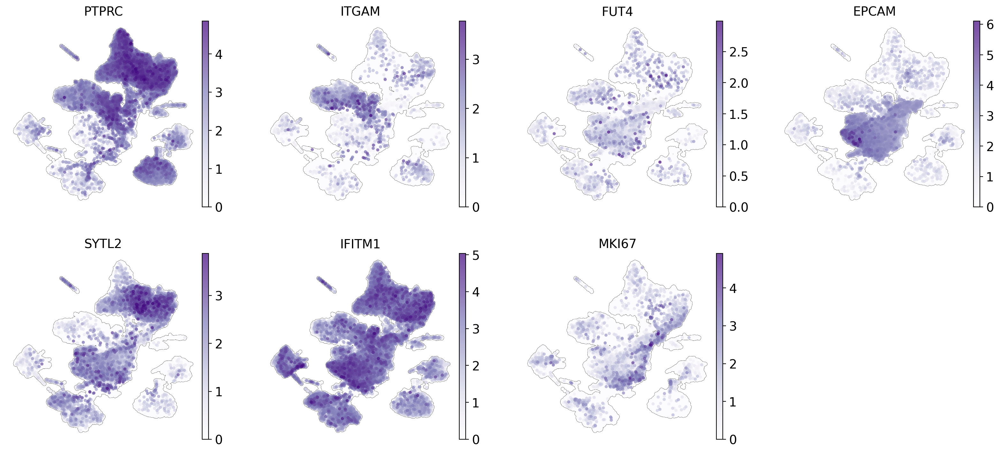

In [3]:
sc.pl.umap(adata, color=['PTPRC', 'ITGAM', 'FUT4', 'EPCAM', 'SYTL2', 'IFITM1', 'MKI67'], legend_loc='right margin', frameon=False, add_outline=True, outline_width=(0.05,0.05), size=50, use_raw=True, cmap='Purples')

In [23]:
sc.tl.rank_genes_groups(adata, groupby='leiden', method='t-test', use_raw=False)

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:02:12)


In [24]:
result = adata.uns['rank_genes_groups']
groups = result['names'].dtype.names
pd.DataFrame(
  {group + '_' + key[:3]: result[key][group]
    for group in groups for key in ['names', 'scores', 'logfoldchanges', 'pvals_adj']}).to_csv("/mnt/c/Users/hyj/Documents/NMCAD_MCAD_markers.csv")

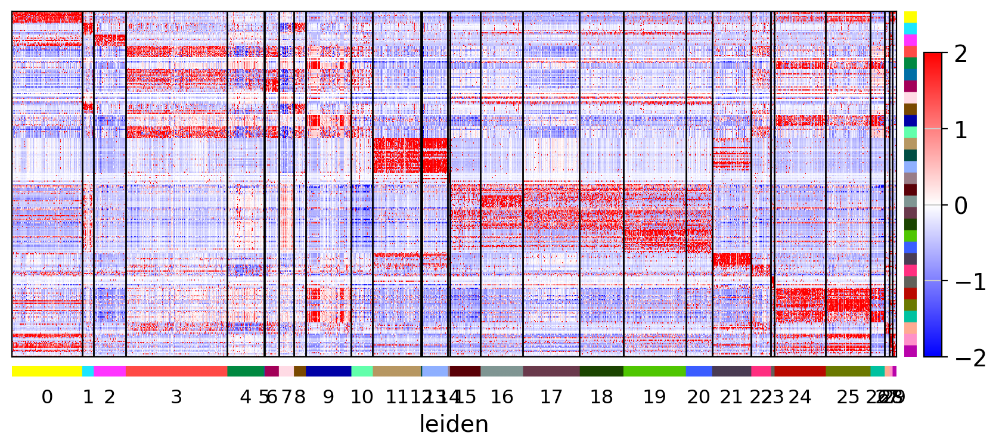

In [25]:
sc.pl.rank_genes_groups_heatmap(adata, n_genes=10, groupby='leiden', use_raw=False, swap_axes=True, vmin=-2, vmax=2, show_gene_labels=False, cmap='bwr', dendrogram=False, save='6.pdf')

In [36]:
# adata.obs['cluster'] = (adata.obs['leiden'].map(lambda x: {'0': '0_B_cells', '1': '1_Cytotoxic_T_cells (proliferating)', '2': '2_Plasma', '3': '3_Parenchymal', '4': '4_Parenchymal', '5': '5_Parenchymal', '6': '6_Parenchymal', '7': '7_Parenchymal', '8': '8_Parenchymal', '9': '9_Neutrophils', '10': '10_Parenchymal', '11': '11_CAF', '12': '12_CAF', '13': '13_CAF', '14': '14_Neurons', '15': '15_CD4⁺ effector/memory T cells', '16': '16_CD4⁺ inflammatory effector T Cells', '17': '17_CD4⁺ effector/memory T cells', '18': '18_CD4⁺ inflammatory effector T Cells', '19': '19_Cytotoxic_T_cells (activated)', '20': '20_NK', '21': '21_Endothelial', '22': '22_Parenchymal', '23': '23_Mast', '24': '24_Macrophages', '25': '25_Macrophages', '26': '26_Macrophages', '27': '27_Parenchymal', '28': '28_Monocytes', '29': '29_DC'}.get(x, x)).astype("category"))

In [8]:
adata.obs['cluster'] = (adata.obs['leiden'].map
                   (lambda x: {'0': 'B',
                               '1': 'T',
                               '2': 'Plasma',
                               '3': 'Parenchymal',
                               '4': 'Parenchymal',
                               '5': 'Parenchymal',
                               '6': 'Parenchymal',
                               '7': 'Parenchymal',
                               '8': 'Parenchymal',
                               '9': 'Neutrophils',
                               '10': 'Parenchymal',
                               '11': 'Fibroblasts',
                               '12': 'Fibroblasts',
                               '13': 'Fibroblasts',
                               '14': 'Neurons',
                               '15': 'T',
                               '16': 'T',
                               '17': 'T',
                               '18': 'T',
                               '19': 'T',
                               '20': 'NK',
                               '21': 'Endothelial',
                               '22': 'Parenchymal',
                               '23': 'Mast',
                               '24': 'Macrophages',
                               '25': 'Macrophages',
                               '26': 'Macrophages',
                               '27': 'Parenchymal',
                               '28': 'Monocytes',
                               '29': 'DCs'}.get(x, x)).astype("category"))

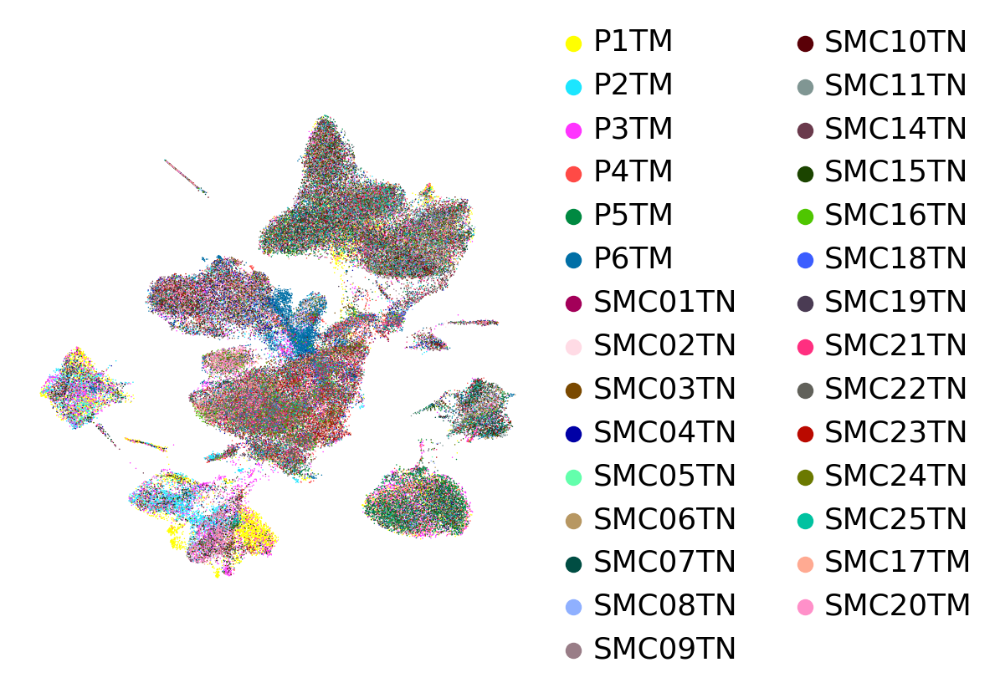

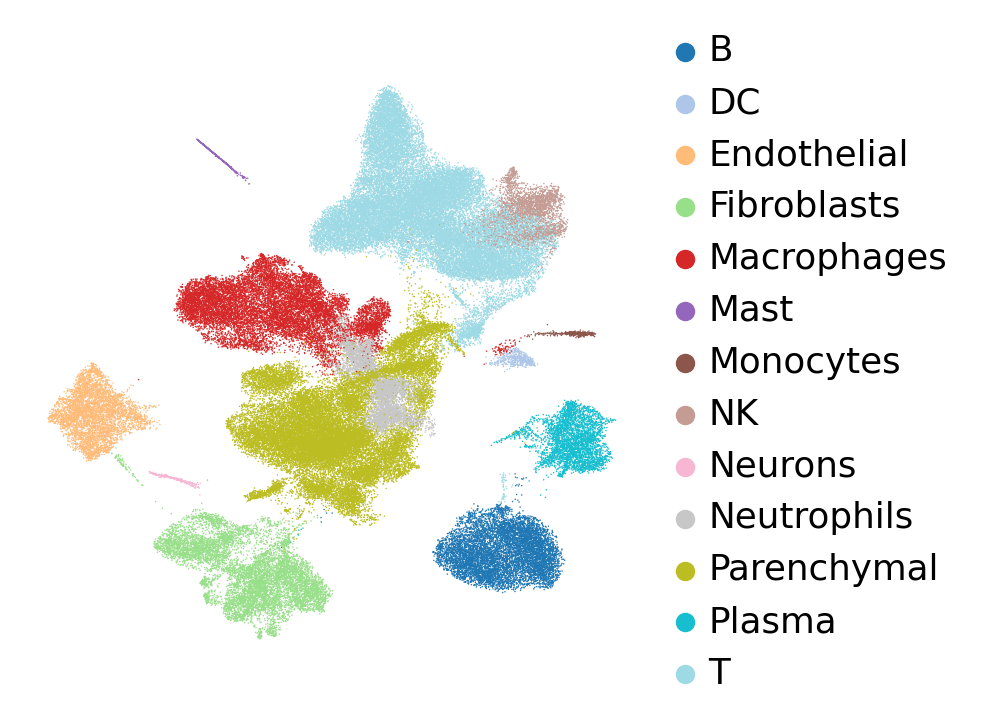

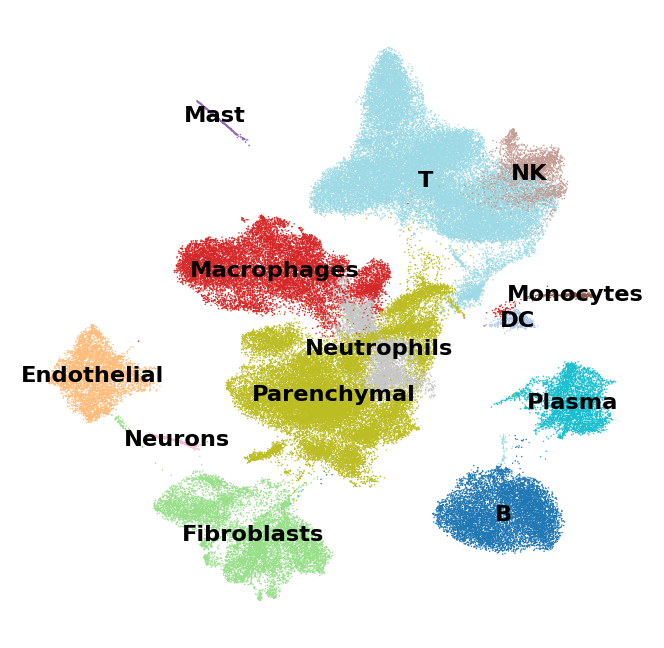

In [18]:
sc.pl.umap(adata, color=['patient'], legend_loc='right margin', frameon=False, title='', use_raw=True, save='1.pdf')
sc.pl.umap(adata, color=['cluster'], legend_loc='right margin', palette='tab20', frameon=False, title='', use_raw=True, save='2.pdf')
sc.pl.umap(adata, color=['cluster'], legend_loc='on data', legend_fontsize='xx-small', palette='tab20', frameon=False, title='', use_raw=True, save='3.pdf')

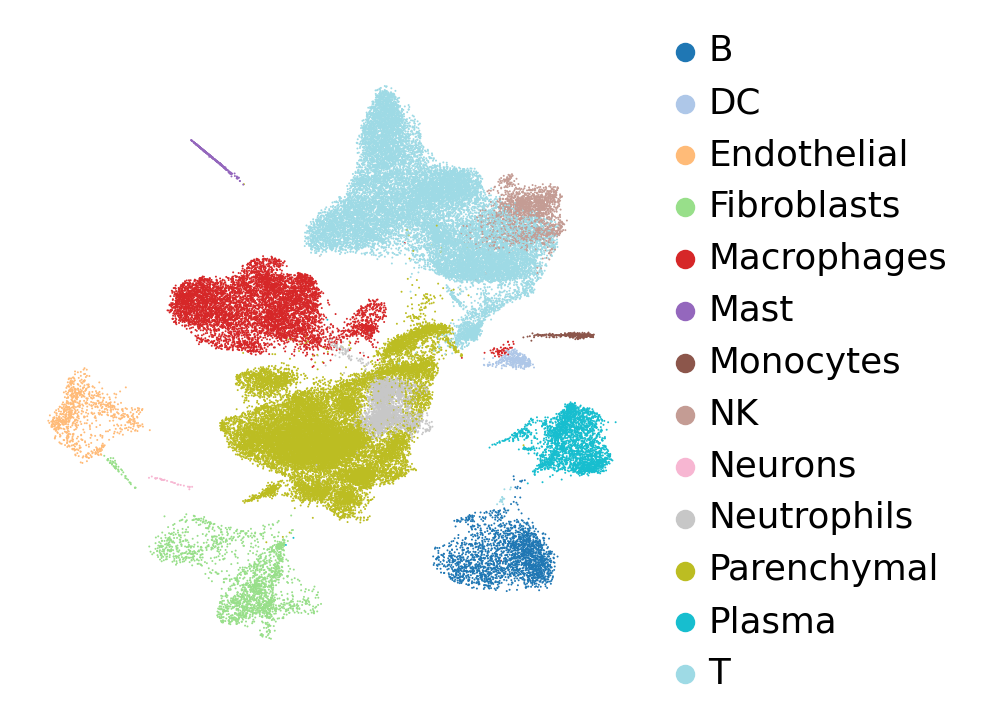

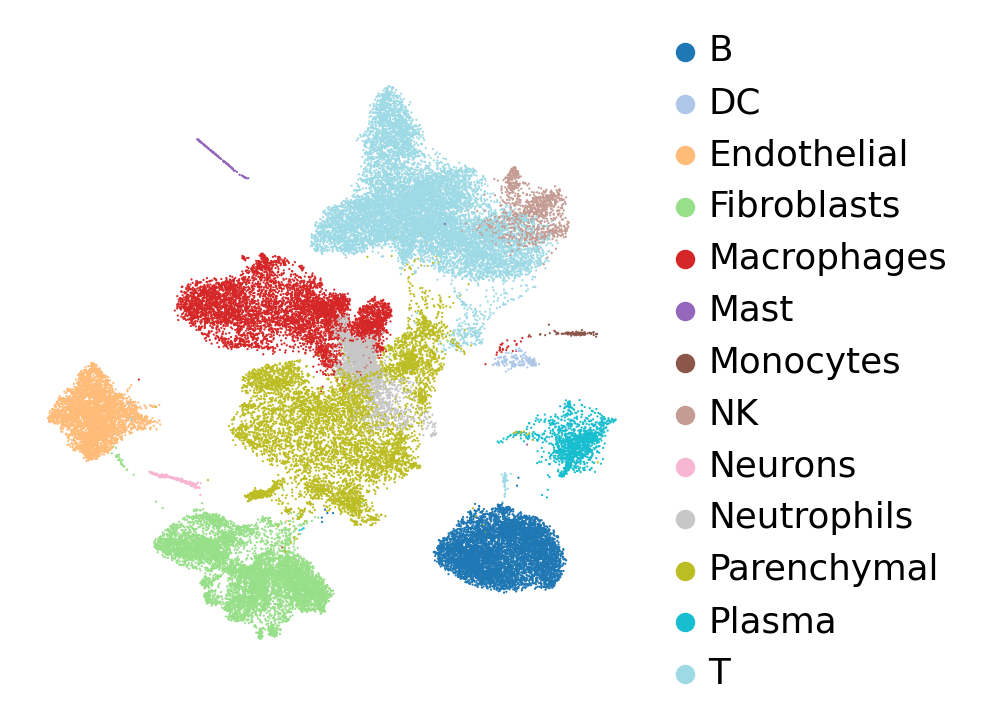

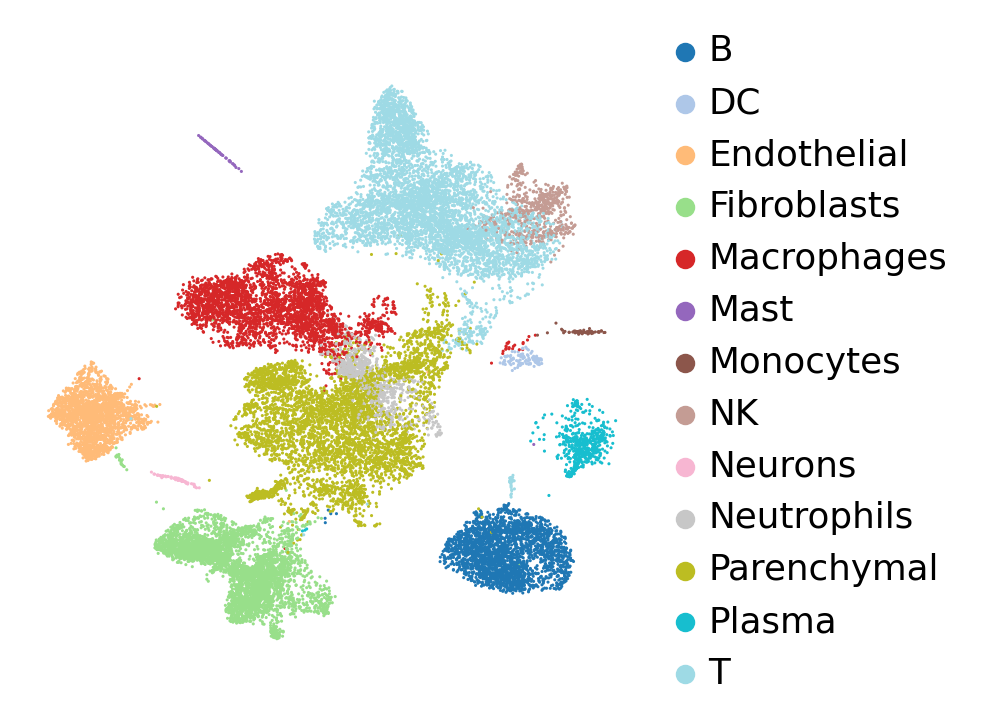

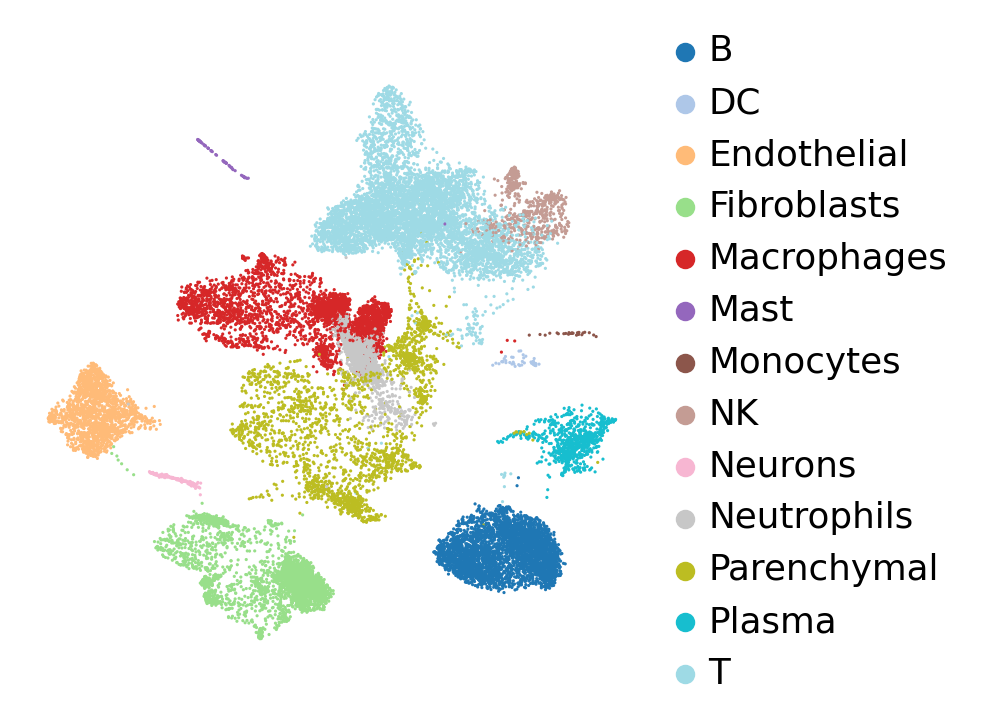

In [19]:
sc.pl.umap(adata[adata.obs['pathology'].isin(['NMCAD'])], color=['cluster'], legend_loc='right margin', frameon=False, title='', use_raw=True, save='4.pdf')
sc.pl.umap(adata[adata.obs['pathology'].isin(['MCAD'])], color=['cluster'], legend_loc='right margin', frameon=False, title='', use_raw=True, save='5.pdf')
sc.pl.umap(adata[adata.obs['patient'].isin(['SMC20TM', 'P3TM', 'P4TM', 'P2TM'])], color=['cluster'], legend_loc='right margin', frameon=False, title='', use_raw=True, save='6.pdf')
sc.pl.umap(adata[adata.obs['patient'].isin(['SMC17TM', 'P1TM', 'P6TM', 'P5TM'])], color=['cluster'],  legend_loc='right margin', frameon=False, title='', use_raw=True, save='7.pdf')

In [14]:
adata.uns['cluster_colors']

['#1f77b4',
 '#aec7e8',
 '#ffbb78',
 '#98df8a',
 '#d62728',
 '#9467bd',
 '#8c564b',
 '#c49c94',
 '#f7b6d2',
 '#c7c7c7',
 '#bcbd22',
 '#17becf',
 '#9edae5']

In [3]:
sc.tl.rank_genes_groups(adata, groupby='cluster', method='t-test', use_raw=False)

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:01:08)


/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:455: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:455: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:455: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:455: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:455: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldc

In [4]:
result = adata.uns['rank_genes_groups']
groups = result['names'].dtype.names
pd.DataFrame(
  {group + '_' + key[:3]: result[key][group]
    for group in groups for key in ['names', 'scores', 'logfoldchanges', 'pvals_adj']}).to_csv("/mnt/c/Users/hyj/Documents/NMCAD_MCAD_cluster_markers.csv")

In [15]:
adata.write('/mnt/c/Users/hyj/Downloads/human_NMCAD_MCAD_adata.h5ad', compression='gzip')

In [2]:
adata = sc.read('/mnt/c/Users/hyj/Downloads/human_NMCAD_MCAD_adata.h5ad')
adata

AnnData object with n_obs × n_vars = 106435 × 5000
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'leiden', 'cluster'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'cluster_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'patient_colors', 'pca', 'rank_genes_groups', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [ ]:
# prepare NMCAD and MCAD data for CellChat

In [48]:
NMCAD=sc.read('/mnt/c/Users/hyj/Downloads/NMCAD.h5ad')
NMCAD

AnnData object with n_obs × n_vars = 70512 × 38606
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset'
    var: 'gene_ids'

In [45]:
processed = sc.read('/mnt/c/Users/hyj/Downloads/human_NMCAD_MCAD_adata.h5ad')
processed

AnnData object with n_obs × n_vars = 106435 × 5000
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'leiden', 'cluster'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'cluster_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'patient_colors', 'pca', 'rank_genes_groups', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [49]:
NMCAD.obs['cluster']=processed.obs['cluster']
NMCAD.obs['cluster']

SMC01T_AAACCTGAGAAGGTTT-1_SMC01T              T
SMC01T_AAACCTGAGGTAGCTG-1_SMC01T              T
SMC01T_AAACCTGAGTCGTACT-1_SMC01T            NaN
SMC01T_AAACCTGCATACGCCG-1_SMC01T              T
SMC01T_AAACCTGGTCATATCG-1_SMC01T              T
                                       ...     
SMC25T_TTTGTCAAGCGCTCCA-1_SMC25T              B
SMC25T_TTTGTCAAGCGTTCCG-1_SMC25T              T
SMC25T_TTTGTCAAGTTCGATC-1_SMC25T    Endothelial
SMC25T_TTTGTCACAAATACAG-1_SMC25T             NK
SMC25T_TTTGTCATCCCAAGTA-1_SMC25T              T
Name: cluster, Length: 70512, dtype: category
Categories (13, object): ['B', 'DC', 'Endothelial', 'Fibroblasts', ..., 'Neutrophils', 'Parenchymal', 'Plasma', 'T']

In [50]:
NMCAD = NMCAD[NMCAD.obs['cluster'].notna()]
NMCAD

View of AnnData object with n_obs × n_vars = 59467 × 38606
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'cluster'
    var: 'gene_ids'

normalizing counts per cell
    finished (0:00:01)


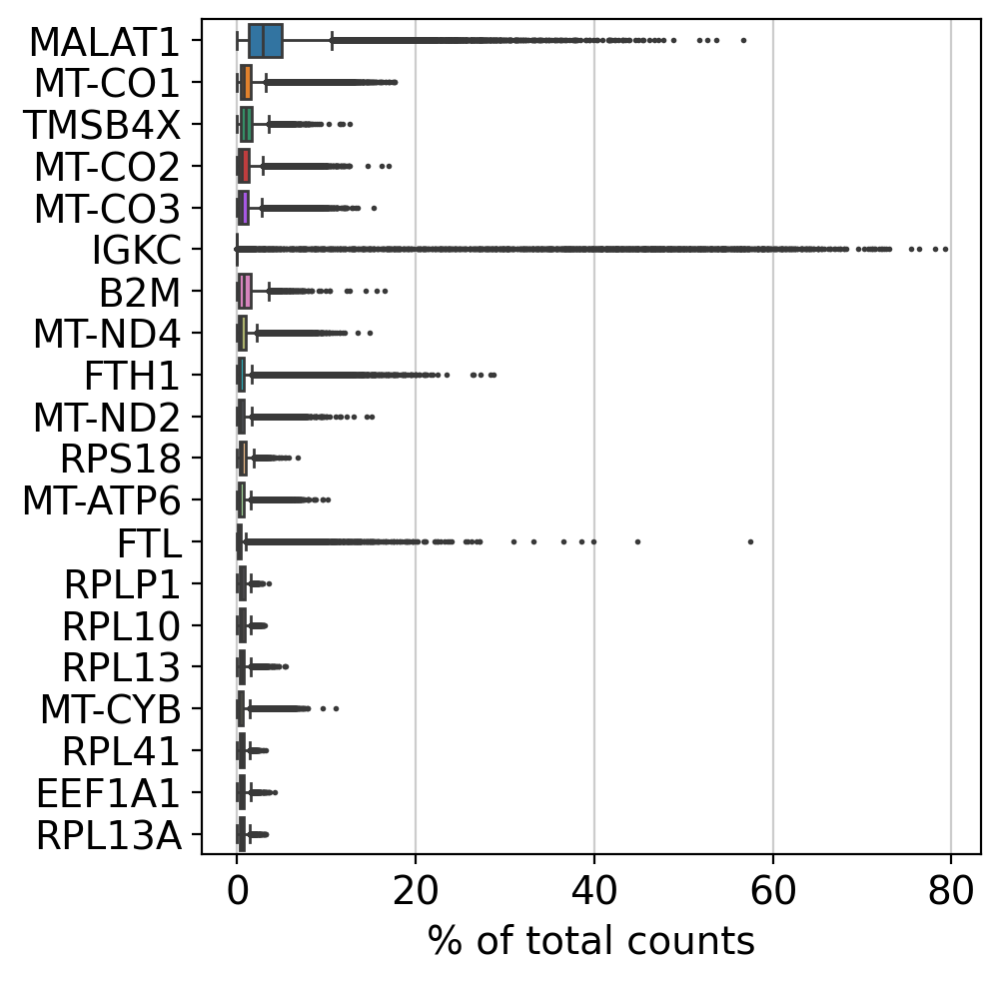

filtered out 10721 genes that are detected in less than 25 cells


In [52]:
sc.pl.highest_expr_genes(NMCAD, n_top=20)
sc.pp.filter_cells(NMCAD, min_genes=100)
sc.pp.filter_genes(NMCAD, min_cells=25)

In [53]:
NMCAD.var['mt'] = NMCAD.var_names.str.startswith('MT-')
NMCAD.var['rpl'] = NMCAD.var_names.str.startswith('RPL')
NMCAD.var['rps'] = NMCAD.var_names.str.startswith('RPS')
NMCAD

AnnData object with n_obs × n_vars = 59467 × 27885
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'cluster', 'n_genes'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps'

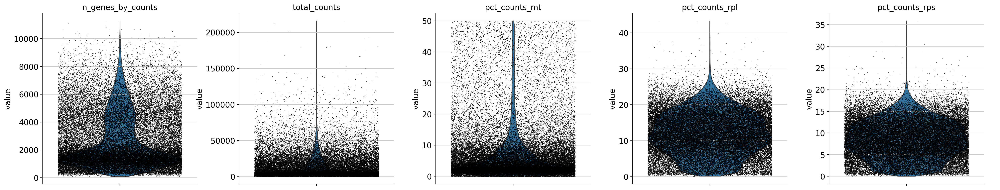

AnnData object with n_obs × n_vars = 59467 × 27885
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'cluster', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

In [54]:
sc.pp.calculate_qc_metrics(NMCAD, qc_vars=['mt','rpl','rps'], percent_top=None, log1p=False, inplace=True)
sc.pl.violin(NMCAD, keys=['n_genes_by_counts', 'total_counts', 'pct_counts_mt','pct_counts_rpl','pct_counts_rps'], jitter=0.4, multi_panel=True)
NMCAD

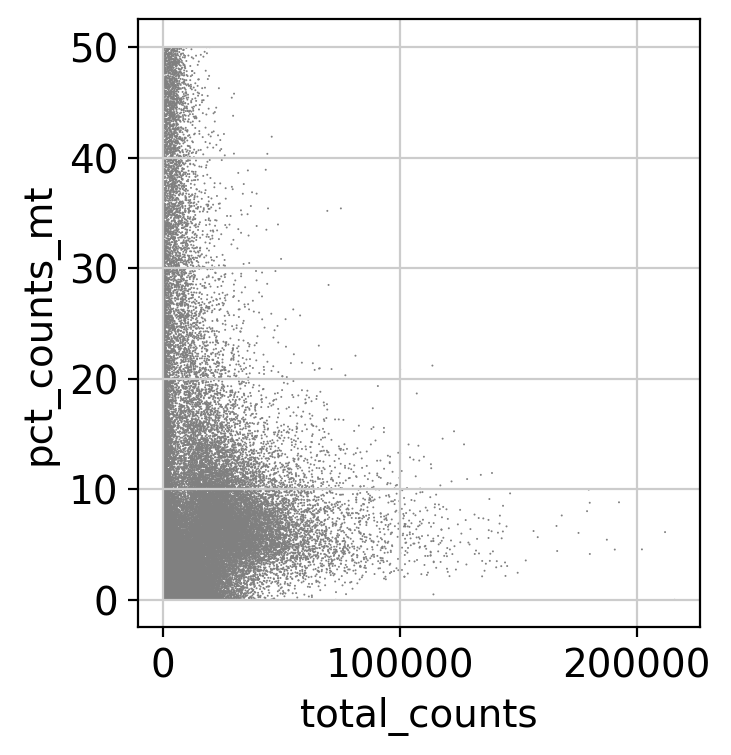

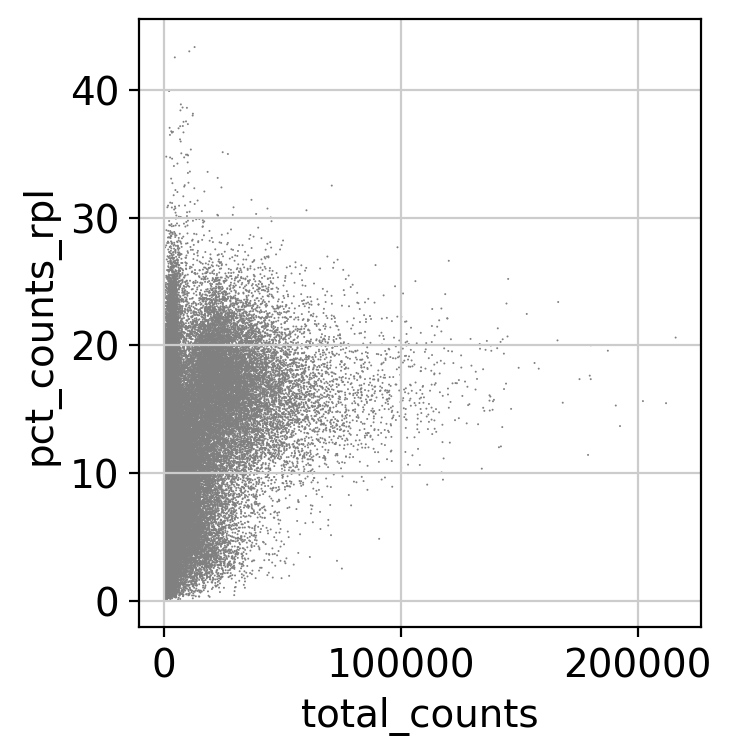

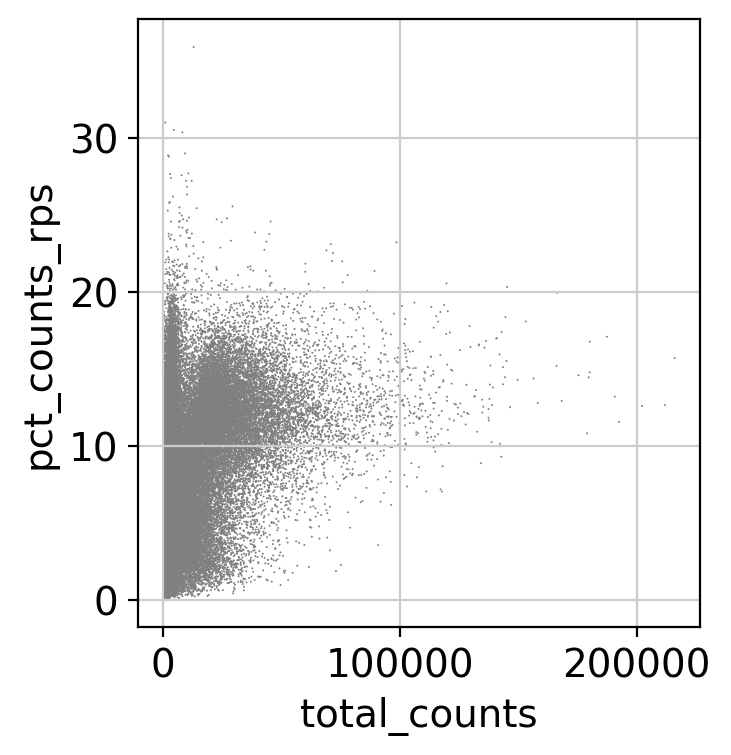

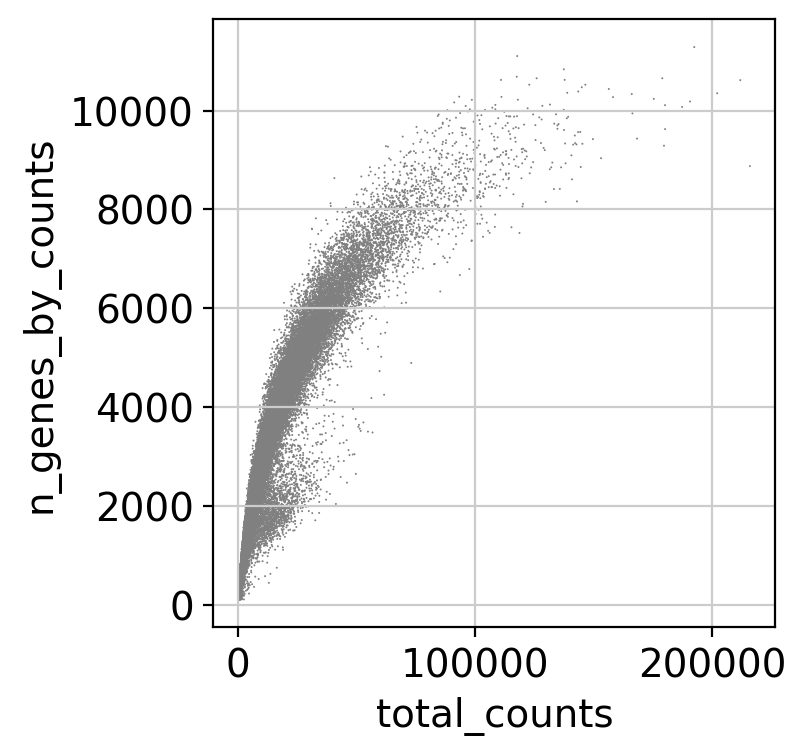

In [55]:
sc.pl.scatter(NMCAD, x='total_counts', y='pct_counts_mt')
sc.pl.scatter(NMCAD, x='total_counts', y='pct_counts_rpl')
sc.pl.scatter(NMCAD, x='total_counts', y='pct_counts_rps')
sc.pl.scatter(NMCAD, x='total_counts', y='n_genes_by_counts')

In [56]:
NMCAD = NMCAD[NMCAD.obs.n_genes_by_counts < 12000, :]
NMCAD = NMCAD[NMCAD.obs.pct_counts_mt < 50, :]
NMCAD = NMCAD[NMCAD.obs.pct_counts_rpl < 50, :]
NMCAD = NMCAD[NMCAD.obs.pct_counts_rps < 50, :]
NMCAD

View of AnnData object with n_obs × n_vars = 59467 × 27885
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'cluster', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

In [57]:
sc.pp.normalize_total(NMCAD, target_sum=1e4)
sc.pp.log1p(NMCAD)
NMCAD

normalizing counts per cell
    finished (0:00:00)


AnnData object with n_obs × n_vars = 59467 × 27885
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'cluster', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'log1p'

In [58]:
NMCAD.write('/mnt/c/Users/hyj/Downloads/human_NMCAD_cellchat.h5ad', compression='gzip')

In [16]:
MCAD=sc.read('/mnt/c/Users/hyj/Downloads/MCAD.h5ad')
MCAD

AnnData object with n_obs × n_vars = 51195 × 38606
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset'
    var: 'gene_ids'

In [17]:
MCAD_low=MCAD[MCAD.obs['patient'].isin(['SMC17TM', 'P1TM', 'P6TM', 'P5TM'])]
MCAD_low

View of AnnData object with n_obs × n_vars = 24106 × 38606
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset'
    var: 'gene_ids'

In [18]:
processed = sc.read('/mnt/c/Users/hyj/Downloads/human_NMCAD_MCAD_adata.h5ad')
processed

AnnData object with n_obs × n_vars = 106435 × 5000
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'leiden', 'cluster'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'cluster_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'patient_colors', 'pca', 'rank_genes_groups', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [19]:
MCAD_low.obs['cluster']=processed.obs['cluster']
MCAD_low.obs['cluster']

/tmp/ipykernel_964/412315942.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  MCAD_low.obs['cluster']=processed.obs['cluster']


P1_T_AAACCCAAGCTCATAC-1_P1_T                  B
P1_T_AAACCCAAGGATATGT-1_P1_T        Parenchymal
P1_T_AAACCCAAGTATAACG-1_P1_T        Fibroblasts
P1_T_AAACCCACAAATGGCG-1_P1_T        Fibroblasts
P1_T_AAACCCACAACTAGAA-1_P1_T                  B
                                       ...     
SMC17T_TTTGGTTCACTCAGGC-1_SMC17T    Parenchymal
SMC17T_TTTGGTTTCCGCAAGC-1_SMC17T    Endothelial
SMC17T_TTTGTCAAGTGCTGCC-1_SMC17T            NaN
SMC17T_TTTGTCATCCACGTGG-1_SMC17T    Parenchymal
SMC17T_TTTGTCATCGTCTGCT-1_SMC17T    Macrophages
Name: cluster, Length: 24106, dtype: category
Categories (13, object): ['B', 'DC', 'Endothelial', 'Fibroblasts', ..., 'Neutrophils', 'Parenchymal', 'Plasma', 'T']

In [20]:
MCAD_low = MCAD_low[MCAD_low.obs['cluster'].notna()]
MCAD_low

View of AnnData object with n_obs × n_vars = 22991 × 38606
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'cluster'
    var: 'gene_ids'

/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


normalizing counts per cell
    finished (0:00:00)


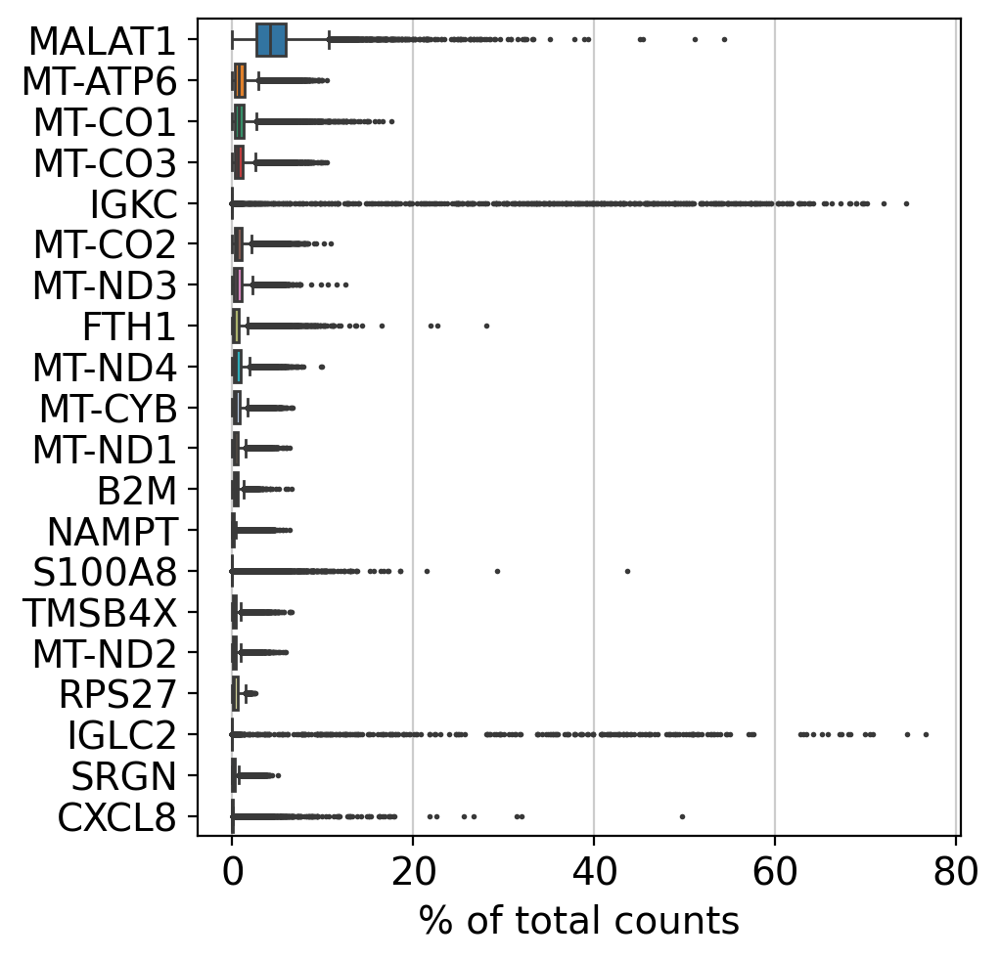

filtered out 13914 genes that are detected in less than 25 cells


AnnData object with n_obs × n_vars = 22991 × 24692
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'cluster', 'n_genes'
    var: 'gene_ids', 'n_cells'

In [21]:
sc.pl.highest_expr_genes(MCAD_low, n_top=20)
sc.pp.filter_cells(MCAD_low, min_genes=100)
sc.pp.filter_genes(MCAD_low, min_cells=25)
MCAD_low

In [22]:
MCAD_low.var['mt'] = MCAD_low.var_names.str.startswith('MT-')
MCAD_low.var['rpl'] = MCAD_low.var_names.str.startswith('RPL')
MCAD_low.var['rps'] = MCAD_low.var_names.str.startswith('RPS')
MCAD_low

AnnData object with n_obs × n_vars = 22991 × 24692
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'cluster', 'n_genes'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps'

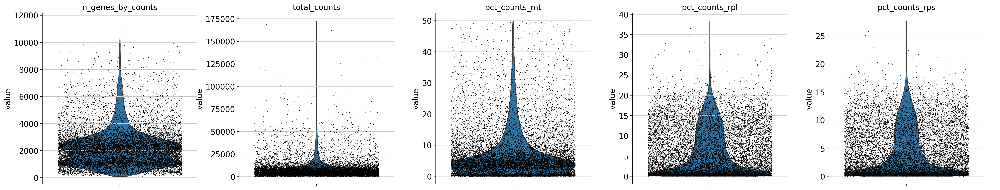

AnnData object with n_obs × n_vars = 22991 × 24692
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'cluster', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

In [23]:
sc.pp.calculate_qc_metrics(MCAD_low, qc_vars=['mt','rpl','rps'], percent_top=None, log1p=False, inplace=True)
sc.pl.violin(MCAD_low, keys=['n_genes_by_counts', 'total_counts', 'pct_counts_mt','pct_counts_rpl','pct_counts_rps'], jitter=0.4, multi_panel=True)
MCAD_low

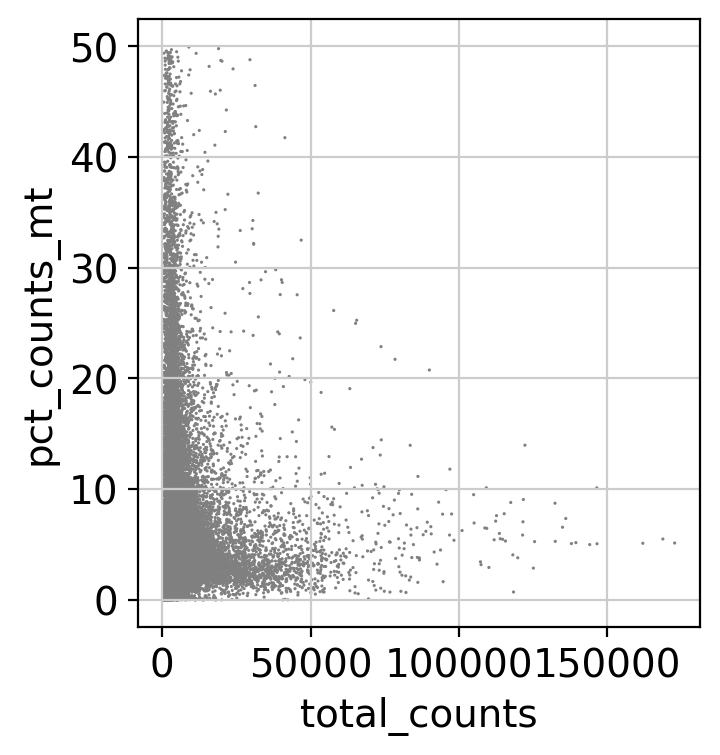

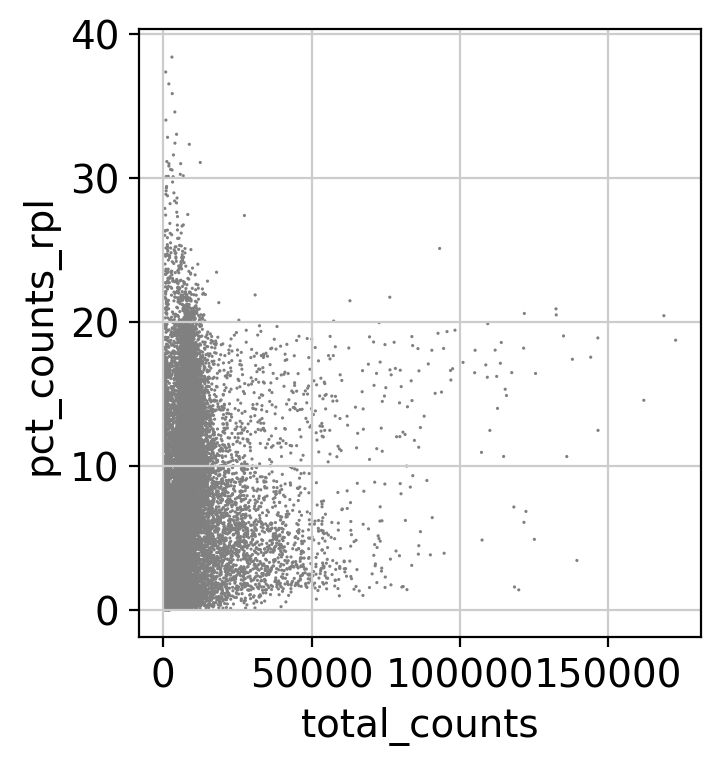

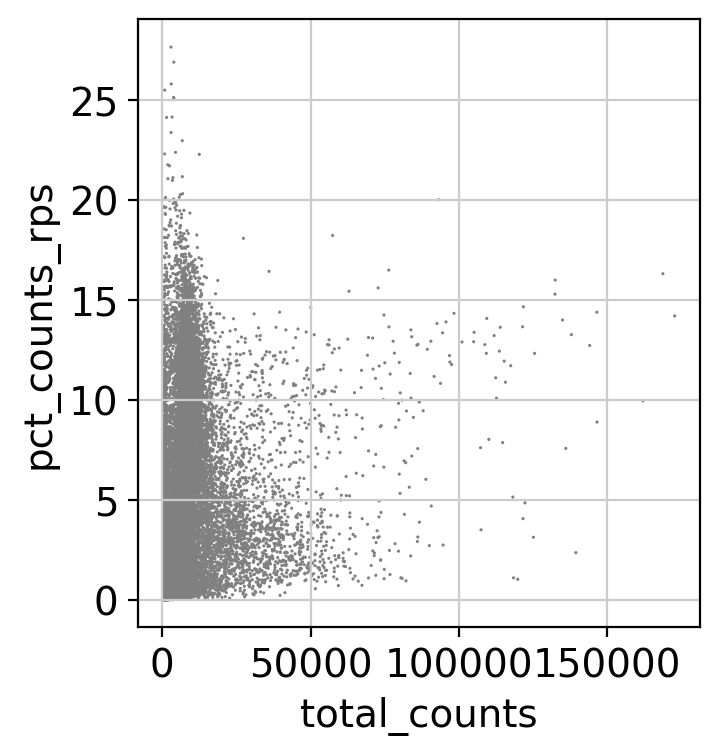

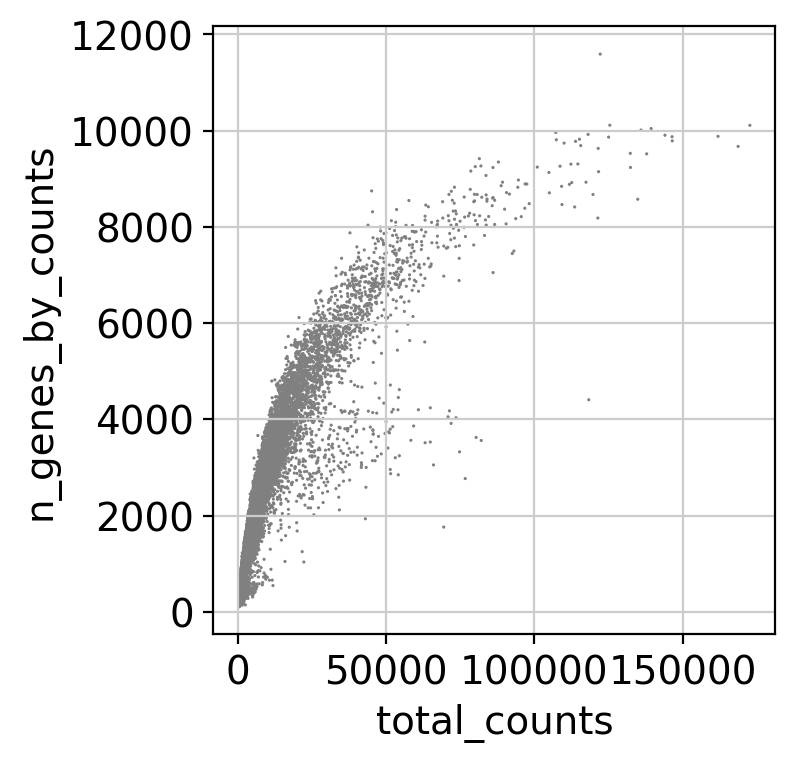

In [24]:
sc.pl.scatter(MCAD_low, x='total_counts', y='pct_counts_mt')
sc.pl.scatter(MCAD_low, x='total_counts', y='pct_counts_rpl')
sc.pl.scatter(MCAD_low, x='total_counts', y='pct_counts_rps')
sc.pl.scatter(MCAD_low, x='total_counts', y='n_genes_by_counts')

In [25]:
MCAD_low = MCAD_low[MCAD_low.obs.n_genes_by_counts < 12000, :]
MCAD_low = MCAD_low[MCAD_low.obs.pct_counts_mt < 50, :]
MCAD_low = MCAD_low[MCAD_low.obs.pct_counts_rpl < 50, :]
MCAD_low = MCAD_low[MCAD_low.obs.pct_counts_rps < 50, :]
MCAD_low

View of AnnData object with n_obs × n_vars = 22991 × 24692
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'cluster', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

In [26]:
sc.pp.normalize_total(MCAD_low, target_sum=1e4)
sc.pp.log1p(MCAD_low)
MCAD_low

/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


normalizing counts per cell
    finished (0:00:00)


AnnData object with n_obs × n_vars = 22991 × 24692
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'cluster', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'log1p'

In [27]:
MCAD_low.write('/mnt/c/Users/hyj/Downloads/human_MCAD_low_cellchat.h5ad', compression='gzip')